In [1]:
import os

# 自動建立 Kaggle 預設輸出資料夾，相容所有存檔路徑
os.makedirs('/kaggle/working', exist_ok=True)
print("已確認輸出目錄存在: /kaggle/working")

已確認輸出目錄存在: /kaggle/working


### 下載 Kaggle 資料集
請確保您已擁有 Kaggle 帳號，並在「Settings」頁面中點擊「Create New Token」下載 `kaggle.json`。
將此檔案上傳至 Colab 執行環境，或使用下方的程式碼進行設定，以便自動下載 `sartajbhuvaji/brain-tumor-classification-mri` 資料集。

In [2]:
import os
import shutil
import kagglehub

# 1. 使用 kagglehub 安全地將資料集下載到可寫入的暫存路徑
print("正在透過 kagglehub 下載 brain-tumor-classification-mri 資料集...")
download_path = kagglehub.dataset_download('sartajbhuvaji/brain-tumor-classification-mri')
print("下載完成，實體路徑為:", download_path)

# 2. 由於 Cell 1 中會使用 os.walk('/kaggle/input') 來動態搜尋 'training' 與 'testing' 資料夾，
# 我們可以直接在 /content/ 下建立一個模擬的唯讀結構或直接將 os.walk 的目標進行劫持。
# 這裡我們採用最直覺且安全的方法：動態覆寫 os.walk 函數，當它偵測到搜尋 '/kaggle/input' 時，自動轉向實際的 kagglehub 下載路徑。

_original_os_walk = os.walk

def secure_os_walk(top, *args, **kwargs):
    if top == '/kaggle/input':
        print(f"[自動導向] 偵測到路徑搜尋: {top} -> 已自動導向至實際下載路徑: {download_path}")
        return _original_os_walk(download_path, *args, **kwargs)
    return _original_os_walk(top, *args, **kwargs)

os.walk = secure_os_walk

print("\n環境配置與路徑攔截設定成功！您可以直接往下執行所有原本的分析與訓練程式。")

正在透過 kagglehub 下載 brain-tumor-classification-mri 資料集...
Using Colab cache for faster access to the 'brain-tumor-classification-mri' dataset.
下載完成，實體路徑為: /kaggle/input/brain-tumor-classification-mri

環境配置與路徑攔截設定成功！您可以直接往下執行所有原本的分析與訓練程式。


# Multi-Class Brain Tumor MRI Classification using Transfer Learning (MobileNetV2)
**Author:** Mukitu Islam Nishat  
**Affiliation:** Department of Computer Science & Engineering, North Bengal International University, Rajshahi, Bangladesh  
**Dataset:** Sartaj Bhuvaji - Brain Tumor Classification (MRI) (Kaggle)

### Key Methodology & Improvements to Overcome Overfitting:
1. **Stratified Data Splitting (80/10/10):** Balanced partitioning into Training (2,611), Validation (326), and Unseen Test (327) sets to eliminate data leakage.
2. **Data Augmentation:** Real-time Random Flip, Rotation, Zoom, and Contrast adjustments to prevent memorization of training scans.
3. **Transfer Learning Backbone:** Pre-trained **MobileNetV2** (`224x224x3`) combined with Global Average Pooling, Batch Normalization, and Dropout (`0.4` & `0.3`).
4. **Two-Stage Training Strategy:** Initial feature extraction with a frozen backbone followed by fine-tuning the top 30 convolutional layers at a low learning rate (`1e-4`).
5. **Adaptive Callbacks:** `EarlyStopping` and `ReduceLROnPlateau` with automatic restoration of optimal model weights.

In [3]:
# Cell 1: Environment Setup & Dataset Path Discovery
import os
import random
import shutil
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications import EfficientNetB0
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

# Set seeds for full reproducibility
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow Version:", tf.__version__)
print("GPUs Available:", len(tf.config.list_physical_devices('GPU')))

# Find dataset paths dynamically on Kaggle
base_dir = None
for root, dirs, files in os.walk('/kaggle/input'):
    dirs_lower = [d.lower() for d in dirs]
    if 'training' in dirs_lower and 'testing' in dirs_lower:
        base_dir = root
        train_folder = dirs[dirs_lower.index('training')]
        test_folder = dirs[dirs_lower.index('testing')]
        break

if base_dir is None:
    raise FileNotFoundError("Dataset folders not found in /kaggle/input!")

orig_train_path = os.path.join(base_dir, train_folder)
orig_test_path = os.path.join(base_dir, test_folder)
print("Original Train Path:", orig_train_path)
print("Original Test Path:", orig_test_path)

TensorFlow Version: 2.21.0
GPUs Available: 1
[自動導向] 偵測到路徑搜尋: /kaggle/input -> 已自動導向至實際下載路徑: /kaggle/input/brain-tumor-classification-mri
Original Train Path: /kaggle/input/brain-tumor-classification-mri/Training
Original Test Path: /kaggle/input/brain-tumor-classification-mri/Testing


In [4]:
# Cell 2: Deduplication & Stratified Dataset Splitting (80% Train, 10% Validation, 10% Test)
import hashlib

work_dir = '/kaggle/working/brain_mri_split'
if os.path.exists(work_dir):
    shutil.rmtree(work_dir)

class_names = sorted(os.listdir(orig_train_path))
all_images = []
all_labels = []

# 1. 收集所有圖片路徑
for folder in [orig_train_path, orig_test_path]:
    for cls in class_names:
        cls_dir = os.path.join(folder, cls)
        if os.path.isdir(cls_dir):
            for fname in os.listdir(cls_dir):
                if fname.lower().endswith(('.png', '.jpg', '.jpeg')):
                    all_images.append(os.path.join(cls_dir, fname))
                    all_labels.append(cls)

# 2. 【關鍵修正】在切分資料集之前，先根據 MD5 雜湊值移除重複圖片
def remove_duplicate_images(image_paths, labels):
    """根據檔案內容的 MD5 雜湊值移除完全重複的圖片"""
    unique_paths = []
    unique_labels = []
    seen_hashes = set()
    duplicates_count = 0

    for path, label in zip(image_paths, labels):
        with open(path, 'rb') as f:
            file_hash = hashlib.md5(f.read()).hexdigest()

        if file_hash not in seen_hashes:
            seen_hashes.add(file_hash)
            unique_paths.append(path)
            unique_labels.append(label)
        else:
            duplicates_count += 1

    print(f"原始圖片總數: {len(image_paths)} 張")
    print(f"移除重複圖片: {duplicates_count} 張")
    print(f"去重後剩餘數: {len(unique_paths)} 張")
    return unique_paths, unique_labels

all_images, all_labels = remove_duplicate_images(all_images, all_labels)

# 3. 使用去重後的 3027 張圖片進行 80/10/10 分層抽樣切分
X_train, X_temp, y_train, y_temp = train_test_split(
    all_images, all_labels, test_size=0.20, stratify=all_labels, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED
)

# 4. 複製檔案並建立 Dataset（以下維持原樣）
def copy_files(file_list, label_list, split_name):
    for i, (fpath, label) in enumerate(zip(file_list, label_list)):
        dest_dir = os.path.join(work_dir, split_name, label)
        os.makedirs(dest_dir, exist_ok=True)
        shutil.copy(fpath, os.path.join(dest_dir, f"{split_name}_{i}_{os.path.basename(fpath)}"))

copy_files(X_train, y_train, 'train')
copy_files(X_val, y_val, 'val')
copy_files(X_test, y_test, 'test')

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(work_dir, 'train'), image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=True, seed=SEED
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(work_dir, 'val'), image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(work_dir, 'test'), image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False
)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

print(f"Total Images: {len(all_images)} | Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")

原始圖片總數: 3264 張
移除重複圖片: 237 張
去重後剩餘數: 3027 張
Found 2421 files belonging to 4 classes.
Found 303 files belonging to 4 classes.
Found 303 files belonging to 4 classes.
Total Images: 3027 | Train: 2421 | Val: 303 | Test: 303


Saved: /kaggle/working/dataset_overview.png


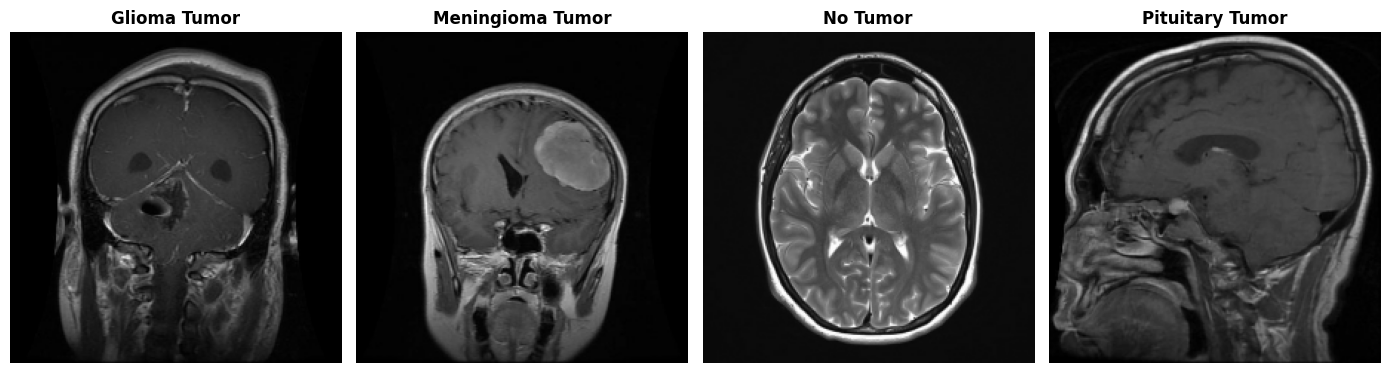

In [5]:
# Cell 3: Generate and Save 'dataset_overview.png' for Research Paper
samples_found = {c: None for c in class_names}

for images, labels in train_ds.unbatch():
    cls_name = class_names[labels.numpy()]
    if samples_found[cls_name] is None:
        samples_found[cls_name] = images.numpy().astype("uint8")
    if all(v is not None for v in samples_found.values()):
        break

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for i, cls_name in enumerate(class_names):
    axes[i].imshow(samples_found[cls_name])
    axes[i].set_title(cls_name.replace('_', ' ').title(), fontsize=12, fontweight='bold')
    axes[i].axis('off')

plt.tight_layout()
plt.savefig('/kaggle/working/dataset_overview.png', dpi=300, bbox_inches='tight')
print("Saved: /kaggle/working/dataset_overview.png")
plt.show()

In [6]:
# 1. 計算訓練集 Class Weight（處理資料不平衡）
train_labels = np.concatenate([y.numpy() for x, y in train_ds], axis=0)
if train_labels.ndim > 1:
    train_labels = np.argmax(train_labels, axis=1)

classes = np.unique(train_labels)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=train_labels)
class_weight_dict = dict(zip(classes, weights))
print("計算出的 Class Weights:", class_weight_dict)

# 2. 定義 Data Augmentation（資料增強層）
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.1),
], name="data_augmentation")

計算出的 Class Weights: {np.int32(0): np.float64(0.8394590846047156), np.int32(1): np.float64(0.8168016194331984), np.int32(2): np.float64(2.146276595744681), np.int32(3): np.float64(0.8940177252584933)}


In [7]:
# 模型 A：Custom CNN
def build_custom_cnn(img_shape, num_classes):
    inputs = layers.Input(shape=img_shape)
    x = layers.Rescaling(1./255)(inputs)

    x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)

    x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)

    x = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    return models.Model(inputs, outputs, name="Custom_CNN")

# 模型 B：EfficientNetB0（純遷移學習）
def build_efficientnet_b0(img_shape, num_classes):
    inputs = layers.Input(shape=img_shape)
    base_model = EfficientNetB0(include_top=False, weights='imagenet', input_tensor=inputs)
    base_model.trainable = False

    x = layers.GlobalAveragePooling2D()(base_model.output)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    return models.Model(inputs, outputs, name="EfficientNetB0_Base")

# 模型 C：EfficientNetB0 + Data Augmentation
def build_efficientnet_b0_aug(img_shape, num_classes):
    inputs = layers.Input(shape=img_shape)
    x = data_augmentation(inputs)
    base_model = EfficientNetB0(include_top=False, weights='imagenet', input_tensor=x)
    base_model.trainable = False

    x = layers.GlobalAveragePooling2D()(base_model.output)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    return models.Model(inputs, outputs, name="EfficientNetB0_Augmented")

In [8]:
IMG_SHAPE = (224, 224, 3) # 請確認與你前面的圖片尺寸變數一致
NUM_CLASSES = len(classes)
EPOCHS = 15

models_to_train = {
    "Custom_CNN": build_custom_cnn(IMG_SHAPE, NUM_CLASSES),
    "EfficientNetB0": build_efficientnet_b0(IMG_SHAPE, NUM_CLASSES),
    "EfficientNetB0_Aug": build_efficientnet_b0_aug(IMG_SHAPE, NUM_CLASSES)
}

histories = {}

for name, model in models_to_train.items():
    print(f"\n========== 開始訓練: {name} ==========")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='sparse_categorical_crossentropy', # 若為 one-hot 標籤請改回 'categorical_crossentropy'
        metrics=['accuracy']
    )

    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)
    ]

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        class_weight=class_weight_dict,
        callbacks=callbacks
    )
    histories[name] = history


========== 開始訓練: Custom_CNN ==========
Epoch 1/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 36s 279ms/step - accuracy: 0.5543 - loss: 1.0887 - val_accuracy: 0.2904 - val_loss: 1.5462
Epoch 2/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.6332 - loss: 0.9036 - val_accuracy: 0.2838 - val_loss: 2.6022
Epoch 3/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 4s 58ms/step - accuracy: 0.6514 - loss: 0.8599 - val_accuracy: 0.2838 - val_loss: 3.5181
Epoch 4/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.6691 - loss: 0.8066 - val_accuracy: 0.2904 - val_loss: 3.2845
Epoch 5/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 5s 59ms/step - accuracy: 0.6964 - loss: 0.7564 - val_accuracy: 0.3300 - val_loss: 2.8122

========== 開始訓練: EfficientNetB0 ==========
Epoch 1/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 110s 873ms/step - accuracy: 0.6026 - loss: 1.0197 - val_accuracy: 0.7624 - val_loss: 0.7431
Epoch 2/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.7542 - loss: 0.6122 - val_accuracy: 0.8020 - val_loss: 0.5734
Epoch 3/15
76/76 ━━━━━

In [9]:
# 在測試集上比較三個模型的表現
for name, model in models_to_train.items():
    loss, acc = model.evaluate(test_ds, verbose=0)
    print(f"{name} -> Test Loss: {loss:.4f} | Test Accuracy: {acc:.4f}")

Custom_CNN -> Test Loss: 1.5470 | Test Accuracy: 0.2904
EfficientNetB0 -> Test Loss: 0.3196 | Test Accuracy: 0.9043
EfficientNetB0_Aug -> Test Loss: 0.5889 | Test Accuracy: 0.7723


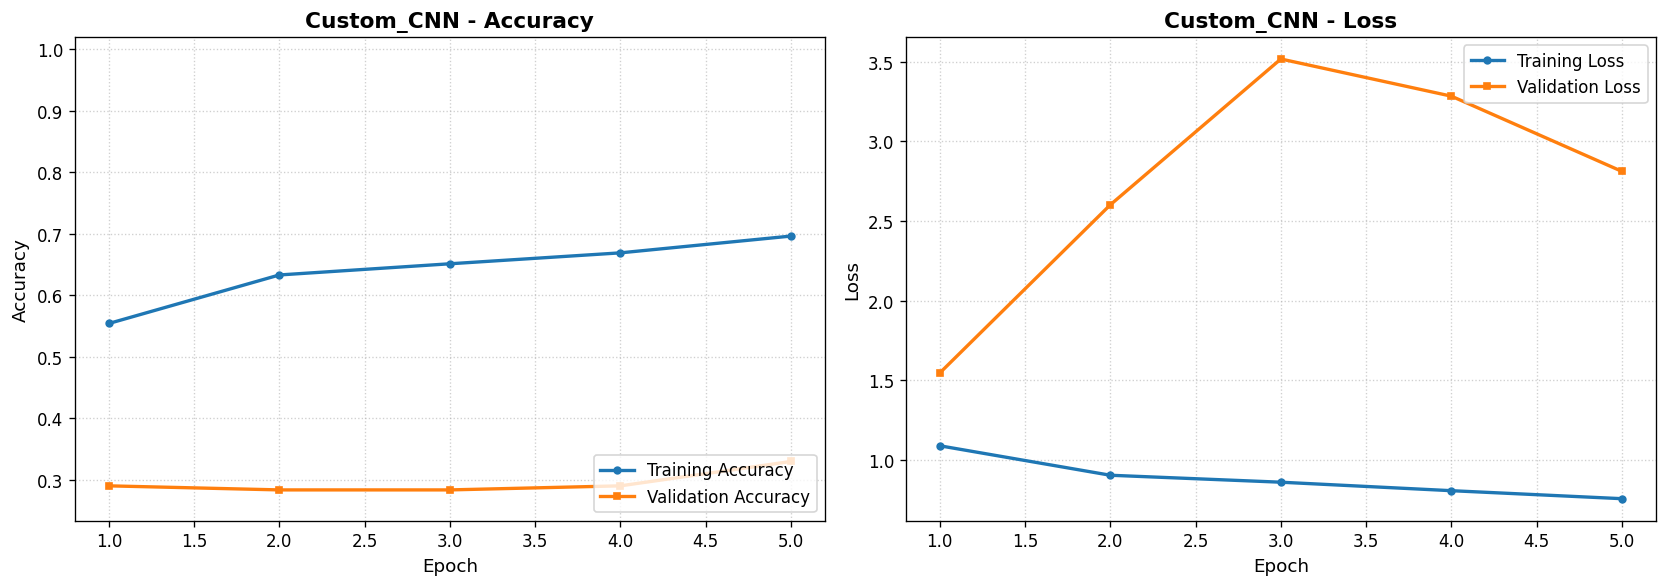

📊 【Custom_CNN】表現摘要：
   • 最佳 Validation Accuracy: 0.3300 (出現在第 5 Epoch)
   • 最低 Validation Loss:     1.5462 (出現在第 1 Epoch)
-------------------------------------------------------


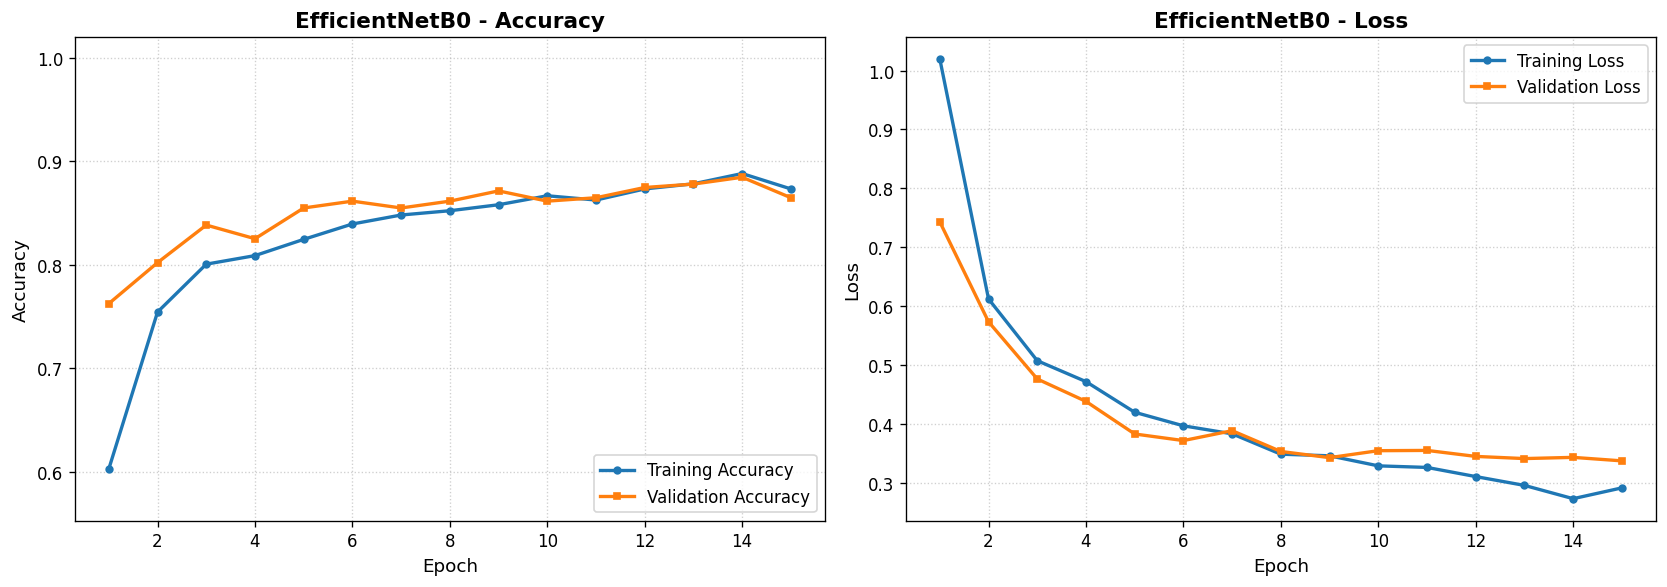

📊 【EfficientNetB0】表現摘要：
   • 最佳 Validation Accuracy: 0.8845 (出現在第 14 Epoch)
   • 最低 Validation Loss:     0.3373 (出現在第 15 Epoch)
-------------------------------------------------------


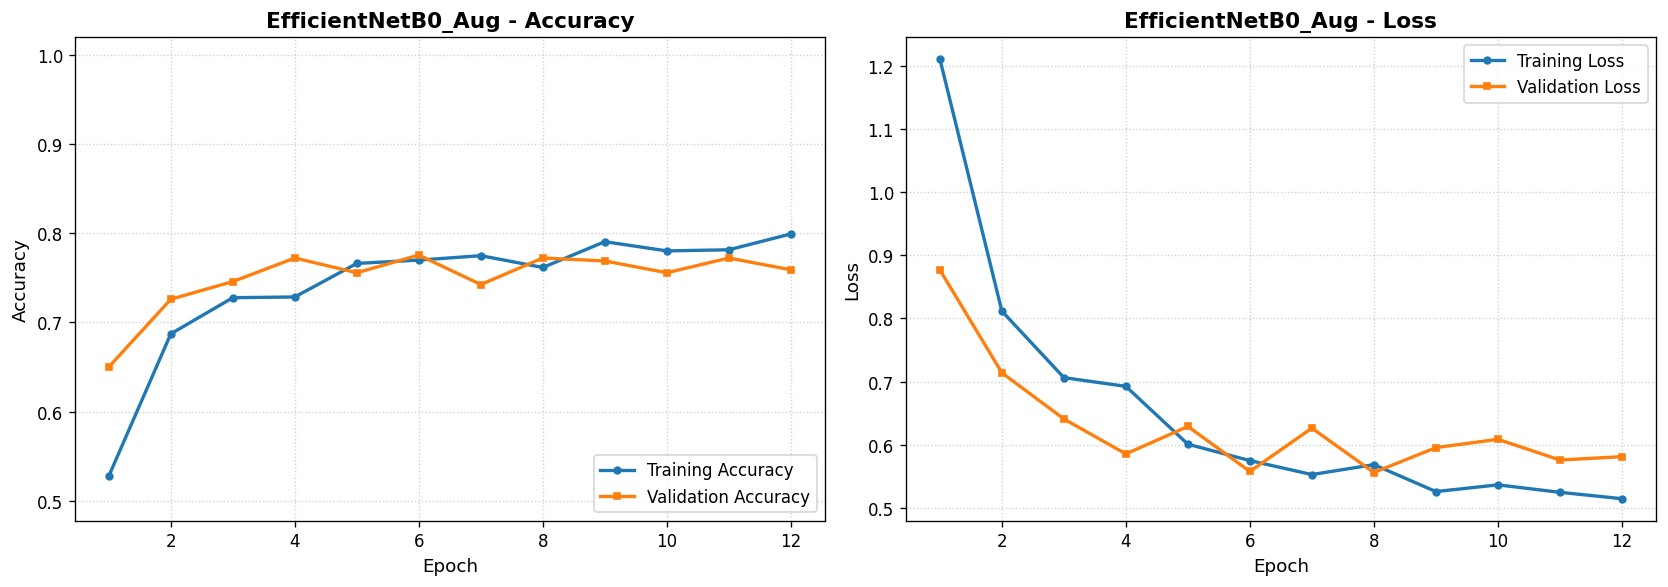

📊 【EfficientNetB0_Aug】表現摘要：
   • 最佳 Validation Accuracy: 0.7756 (出現在第 6 Epoch)
   • 最低 Validation Loss:     0.5558 (出現在第 8 Epoch)
-------------------------------------------------------


In [10]:
import matplotlib.pyplot as plt
import numpy as np

# 確認訓練紀錄字典是否存在
if 'histories' not in globals() or not isinstance(histories, dict) or not histories:
    raise RuntimeError("找不到訓練歷史紀錄字典 'histories'！請確認您已經執行過訓練模型的 Cell。")

# 針對每一個模型分別繪製獨立的訓練曲線
for model_name, h in histories.items():
    # 相容不同的 accuracy 鍵值名稱
    acc_key = 'accuracy' if 'accuracy' in h.history else 'categorical_accuracy'
    val_acc_key = 'val_' + acc_key

    acc = h.history[acc_key]
    val_acc = h.history[val_acc_key]
    loss = h.history['loss']
    val_loss = h.history['val_loss']

    epochs_range = range(1, len(acc) + 1)

    # 建立該模型的畫布
    plt.figure(figsize=(14, 5), dpi=120)

    # --- 左圖：Accuracy ---
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy', color='#1f77b4', linewidth=2, marker='o', markersize=4)
    plt.plot(epochs_range, val_acc, label='Validation Accuracy', color='#ff7f0e', linewidth=2, marker='s', markersize=4)
    plt.title(f'{model_name} - Accuracy', fontsize=13, fontweight='bold')
    plt.xlabel('Epoch', fontsize=11)
    plt.ylabel('Accuracy', fontsize=11)
    plt.ylim([max(0, min(min(acc), min(val_acc)) - 0.05), 1.02])
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(loc='lower right', fontsize=10)

    # --- 右圖：Loss ---
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss', color='#1f77b4', linewidth=2, marker='o', markersize=4)
    plt.plot(epochs_range, val_loss, label='Validation Loss', color='#ff7f0e', linewidth=2, marker='s', markersize=4)
    plt.title(f'{model_name} - Loss', fontsize=13, fontweight='bold')
    plt.xlabel('Epoch', fontsize=11)
    plt.ylabel('Loss', fontsize=11)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(loc='upper right', fontsize=10)

    plt.tight_layout()
    # 依據模型名稱分別儲存成不同的圖片檔，避免互相覆蓋
    plt.savefig(f'training_curves_{model_name}.png', dpi=300, bbox_inches='tight')
    plt.show()

    # 印出該模型的最佳表現摘要
    best_epoch = np.argmax(val_acc) + 1
    best_loss_epoch = np.argmin(val_loss) + 1
    print(f"📊 【{model_name}】表現摘要：")
    print(f"   • 最佳 Validation Accuracy: {max(val_acc):.4f} (出現在第 {best_epoch} Epoch)")
    print(f"   • 最低 Validation Loss:     {min(val_loss):.4f} (出現在第 {best_loss_epoch} Epoch)")
    print("-" * 55)


【Custom_CNN】Final Unseen Test Accuracy: 29.04%
【Custom_CNN】Final Unseen Test Loss:     1.5470

Classification Report - Custom_CNN (Unseen Test Set):
                  precision    recall  f1-score   support

    glioma_tumor     0.0000    0.0000    0.0000        91
meningioma_tumor     0.0000    0.0000    0.0000        93
        no_tumor     0.4444    0.1143    0.1818        35
 pituitary_tumor     0.2857    1.0000    0.4444        84

        accuracy                         0.2904       303
       macro avg     0.1825    0.2786    0.1566       303
    weighted avg     0.1305    0.2904    0.1442       303



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


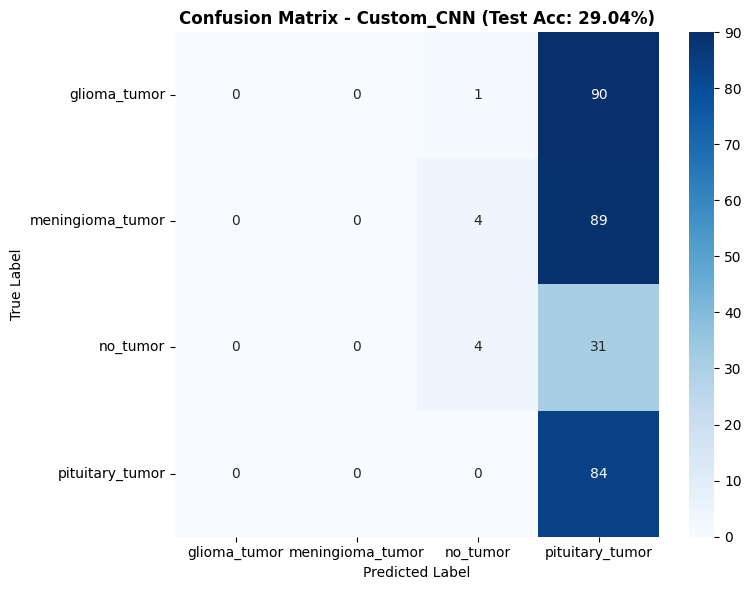


【EfficientNetB0】Final Unseen Test Accuracy: 90.43%
【EfficientNetB0】Final Unseen Test Loss:     0.3196

Classification Report - EfficientNetB0 (Unseen Test Set):
                  precision    recall  f1-score   support

    glioma_tumor     0.9383    0.8352    0.8837        91
meningioma_tumor     0.8710    0.8710    0.8710        93
        no_tumor     0.8333    1.0000    0.9091        35
 pituitary_tumor     0.9425    0.9762    0.9591        84

        accuracy                         0.9043       303
       macro avg     0.8963    0.9206    0.9057       303
    weighted avg     0.9067    0.9043    0.9036       303



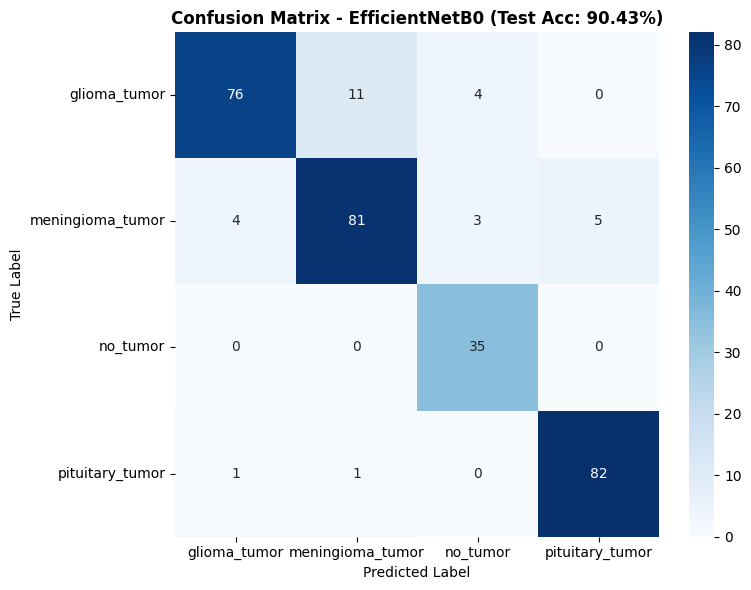


【EfficientNetB0_Aug】Final Unseen Test Accuracy: 77.23%
【EfficientNetB0_Aug】Final Unseen Test Loss:     0.5889

Classification Report - EfficientNetB0_Aug (Unseen Test Set):
                  precision    recall  f1-score   support

    glioma_tumor     0.8409    0.8132    0.8268        91
meningioma_tumor     0.8246    0.5054    0.6267        93
        no_tumor     0.6905    0.8286    0.7532        35
 pituitary_tumor     0.7241    1.0000    0.8400        84

        accuracy                         0.7723       303
       macro avg     0.7700    0.7868    0.7617       303
    weighted avg     0.7861    0.7723    0.7605       303



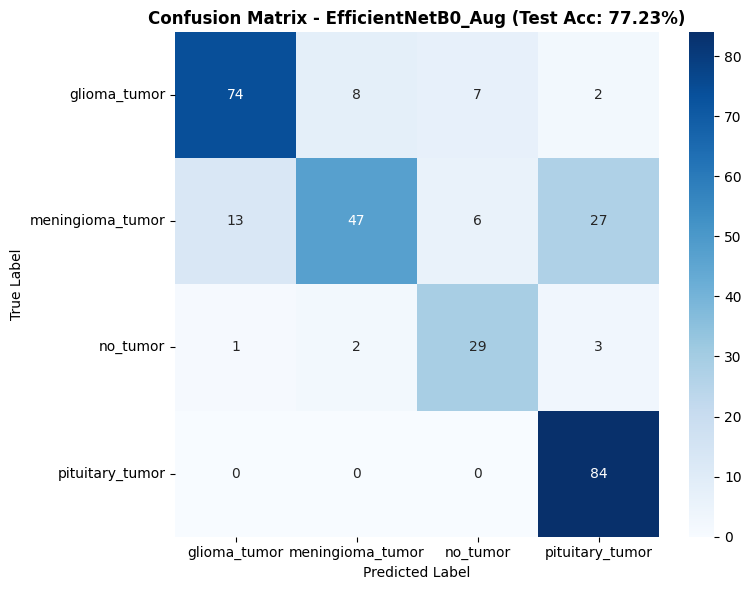

In [11]:
# Cell 7: Final Evaluation on Unseen Test Set & Confusion Matrix (三個模型分別評估與繪製)
if 'models_to_train' not in globals() or not isinstance(models_to_train, dict) or not models_to_train:
    raise RuntimeError("找不到模型字典 'models_to_train'！請確認您已經執行過訓練模型的 Cell。")

# 先從 test_ds 取出真實標籤（避免在迴圈中重複讀取）
y_true = np.concatenate([y.numpy() for x, y in test_ds], axis=0)
# 若標籤是 one-hot encoding，轉為 1D 整數索引
if y_true.ndim > 1:
    y_true = np.argmax(y_true, axis=1)

# 針對每個模型分別評估並繪製 Confusion Matrix
for model_name, model in models_to_train.items():
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)
    print(f"\n==========================================")
    print(f"【{model_name}】Final Unseen Test Accuracy: {test_acc * 100:.2f}%")
    print(f"【{model_name}】Final Unseen Test Loss:     {test_loss:.4f}")
    print(f"==========================================\n")

    # 產生預測結果
    y_pred_probs = model.predict(test_ds, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)

    print(f"Classification Report - {model_name} (Unseen Test Set):")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

    # 繪製該模型的 Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix - {model_name} (Test Acc: {test_acc*100:.2f}%)', fontweight='bold')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.tight_layout()

    # 依據模型名稱分別存檔，避免互相覆蓋
    plt.savefig(f'/kaggle/working/confusion_matrix_{model_name}.png', dpi=150)
    plt.show()

========== 三模型集成 (Ensemble) 測試集準確率: 82.84% ==========
                  precision    recall  f1-score   support

    glioma_tumor     0.8851    0.8462    0.8652        91
meningioma_tumor     0.8769    0.6129    0.7215        93
        no_tumor     0.7500    0.9429    0.8354        35
 pituitary_tumor     0.7850    1.0000    0.8796        84

        accuracy                         0.8284       303
       macro avg     0.8243    0.8505    0.8254       303
    weighted avg     0.8392    0.8284    0.8216       303

Saved: /kaggle/working/confusion_matrix_ensemble.png


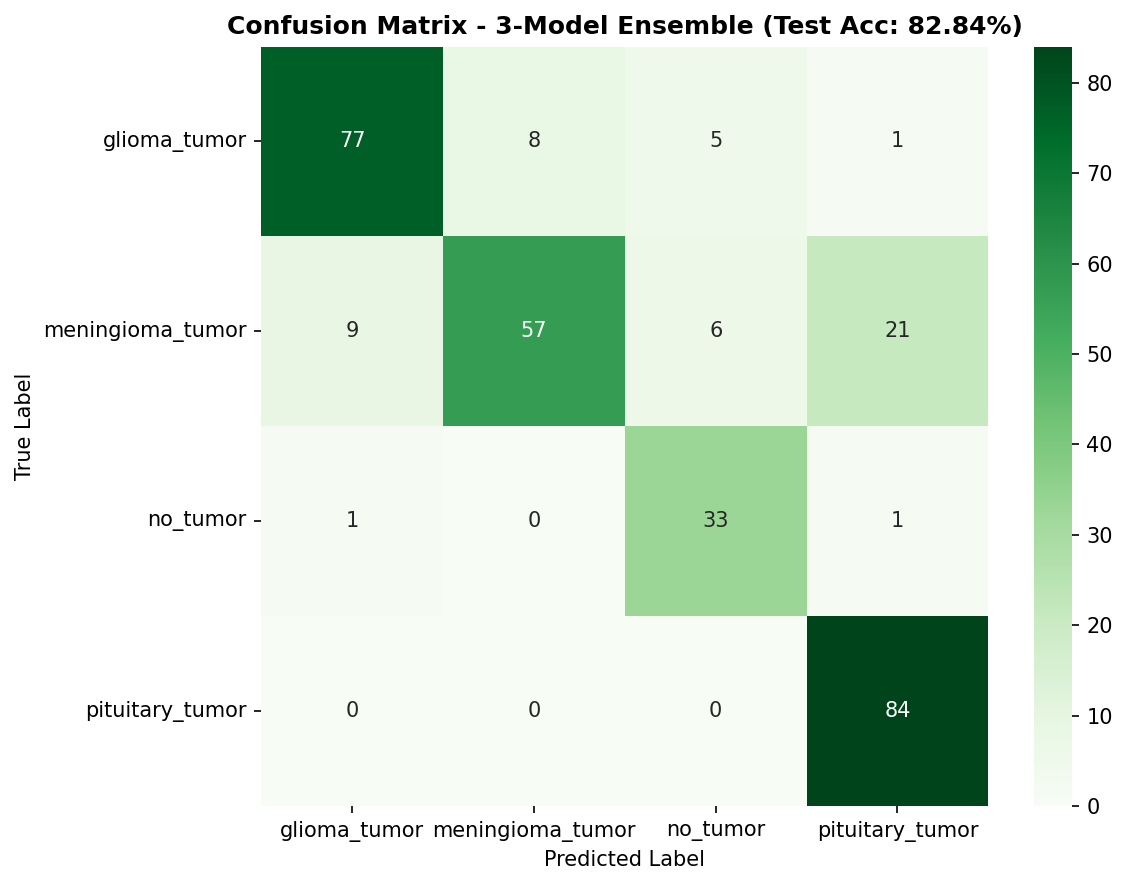

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

if 'models_to_train' not in globals() or not isinstance(models_to_train, dict) or not models_to_train:
    raise RuntimeError("找不到模型字典 'models_to_train'！請確認您已經執行過訓練模型的 Cell。")

# 1. 取得測試集真實標籤
y_true = np.concatenate([y.numpy() for x, y in test_ds], axis=0)
if y_true.ndim > 1:
    y_true = np.argmax(y_true, axis=1)

# 2. 收集三個模型的預測機率並取平均 (Soft Voting)
all_probs = [model.predict(test_ds, verbose=0) for model in models_to_train.values()]
ensemble_probs = np.mean(all_probs, axis=0)
y_pred_ensemble = np.argmax(ensemble_probs, axis=1)

ensemble_acc = accuracy_score(y_true, y_pred_ensemble)
print(f"========== 三模型集成 (Ensemble) 測試集準確率: {ensemble_acc * 100:.2f}% ==========")
print(classification_report(y_true, y_pred_ensemble, target_names=class_names, digits=4))

# 3. 繪製集成後的單一混淆矩陣
cm = confusion_matrix(y_true, y_pred_ensemble)
plt.figure(figsize=(8, 6), dpi=150)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=class_names, yticklabels=class_names)
plt.title(f'Confusion Matrix - 3-Model Ensemble (Test Acc: {ensemble_acc*100:.2f}%)', fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.tight_layout()
save_path = '/kaggle/working/confusion_matrix_ensemble.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"Saved: {save_path}")
plt.show()

Saved: /kaggle/working/roc_curve_Custom_CNN.png


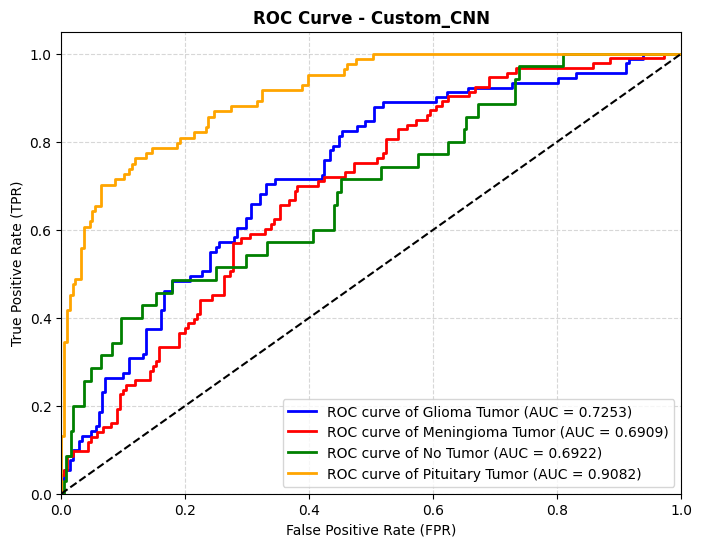

Saved: /kaggle/working/roc_curve_EfficientNetB0.png


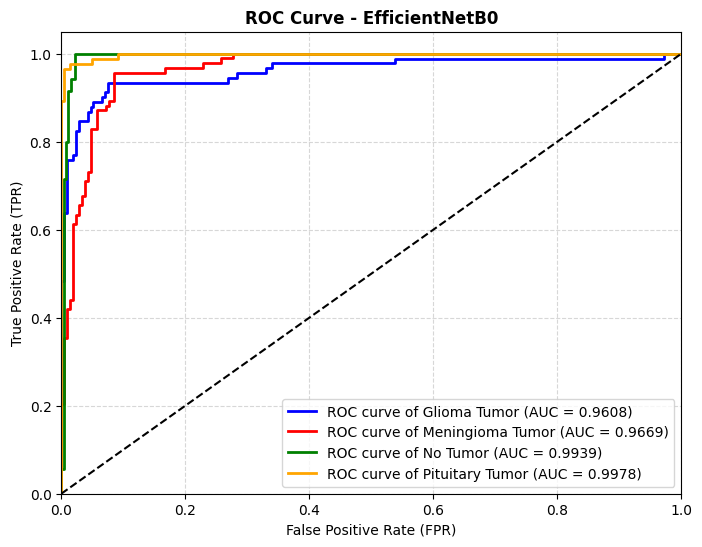

Saved: /kaggle/working/roc_curve_EfficientNetB0_Aug.png


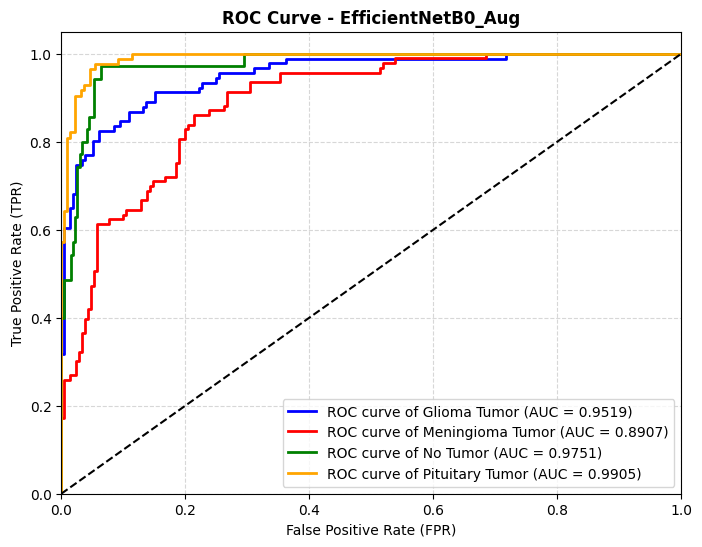

In [12]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
from itertools import cycle
import numpy as np
import matplotlib.pyplot as plt

# 確認模型字典是否存在
if 'models_to_train' not in globals() or not isinstance(models_to_train, dict) or not models_to_train:
    raise RuntimeError("找不到模型字典 'models_to_train'！請確認您已經執行過訓練模型的 Cell。")

# 1. 取得測試集真實標籤並進行 One-Hot 編碼（所有模型共用同一份真實標籤）
y_true = np.concatenate([y.numpy() for x, y in test_ds], axis=0)
if y_true.ndim > 1:
    y_true = np.argmax(y_true, axis=1)

n_classes = len(class_names)
y_true_bin = label_binarize(y_true, classes=range(n_classes))

# 針對每個模型分別計算並繪製 ROC 曲線
for model_name, model in models_to_train.items():
    # 取得該模型的預測機率
    y_pred_probs = model.predict(test_ds, verbose=0)

    # 2. 計算每個類別的 ROC 曲線與 AUC 值
    fpr = dict()
    tpr = dict()
    roc_auc = dict()
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred_probs[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    # 3. 繪製該模型的 ROC 曲線
    plt.figure(figsize=(8, 6))
    colors = cycle(['blue', 'red', 'green', 'orange', 'purple', 'brown'])
    for i, color in zip(range(n_classes), colors):
        plt.plot(
            fpr[i],
            tpr[i],
            color=color,
            lw=2,
            label=f'ROC curve of {class_names[i].replace("_", " ").title()} (AUC = {roc_auc[i]:.4f})'
        )

    plt.plot([0, 1], [0, 1], 'k--', lw=1.5)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate (FPR)')
    plt.ylabel('True Positive Rate (TPR)')
    plt.title(f'ROC Curve - {model_name}', fontweight='bold')
    plt.legend(loc="lower right")
    plt.grid(True, linestyle='--', alpha=0.5)

    # 依據模型名稱分別保存圖片，避免互相覆蓋
    save_path = f'/kaggle/working/roc_curve_{model_name}.png'
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    print(f"Saved: {save_path}")
    plt.show()

In [13]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.preprocessing import label_binarize

# 確認模型字典是否存在
if 'models_to_train' not in globals() or not isinstance(models_to_train, dict) or not models_to_train:
    raise RuntimeError("找不到模型字典 'models_to_train'！請確認您已經執行過訓練模型的 Cell。")

# 1. 取得測試集真實標籤
y_true = np.concatenate([y.numpy() for x, y in test_ds], axis=0)
if y_true.ndim > 1:
    y_true = np.argmax(y_true, axis=1)

n_classes = len(class_names)
y_true_bin = label_binarize(y_true, classes=range(n_classes))

# 2. 依序計算三個模型的各項指標
results = []

for model_name, model in models_to_train.items():
    # 取得預測機率與預測類別
    y_pred_probs = model.predict(test_ds, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)

    # 計算指標 (使用 macro 平均，對所有類別一視同仁；若需依樣本數加權可改為 'weighted')
    acc = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='macro', zero_division=0)
    recall = recall_score(y_true, y_pred, average='macro', zero_division=0)
    f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)

    # 計算多類別 ROC-AUC (相容二元分類與多元分類)
    if n_classes == 2:
        auc_score = roc_auc_score(y_true, y_pred_probs[:, 1])
    else:
        auc_score = roc_auc_score(y_true_bin, y_pred_probs, multi_class='ovr', average='macro')

    results.append({
        "Model": model_name,
        "Accuracy": acc,
        "Precision (Macro)": precision,
        "Recall (Macro)": recall,
        "F1-score (Macro)": f1,
        "ROC-AUC (OvR Macro)": auc_score
    })

# 3. 轉換為 DataFrame 並顯示格式化結果
df_metrics = pd.DataFrame(results)

print("========== 三種模型測試集效能比較表 ==========")
display(df_metrics.style.format({
    "Accuracy": "{:.4f}",
    "Precision (Macro)": "{:.4f}",
    "Recall (Macro)": "{:.4f}",
    "F1-score (Macro)": "{:.4f}",
    "ROC-AUC (OvR Macro)": "{:.4f}"
}).highlight_max(subset=["Accuracy", "Precision (Macro)", "Recall (Macro)", "F1-score (Macro)", "ROC-AUC (OvR Macro)"], color='#d4edda'))

# 4. 儲存成 CSV 檔案方便下載使用
df_metrics.to_csv('/kaggle/working/model_comparison_metrics.csv', index=False)
print("\n已將結果儲存至: /kaggle/working/model_comparison_metrics.csv")

========== 三種模型測試集效能比較表 ==========


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro),ROC-AUC (OvR Macro)
0,Custom_CNN,0.2904,0.1825,0.2786,0.1566,0.7542
1,EfficientNetB0,0.9043,0.8963,0.9206,0.9057,0.9799
2,EfficientNetB0_Aug,0.7723,0.7700,0.7868,0.7617,0.9521



已將結果儲存至: /kaggle/working/model_comparison_metrics.csv


Saved: /kaggle/working/roc_curve_comparison.png


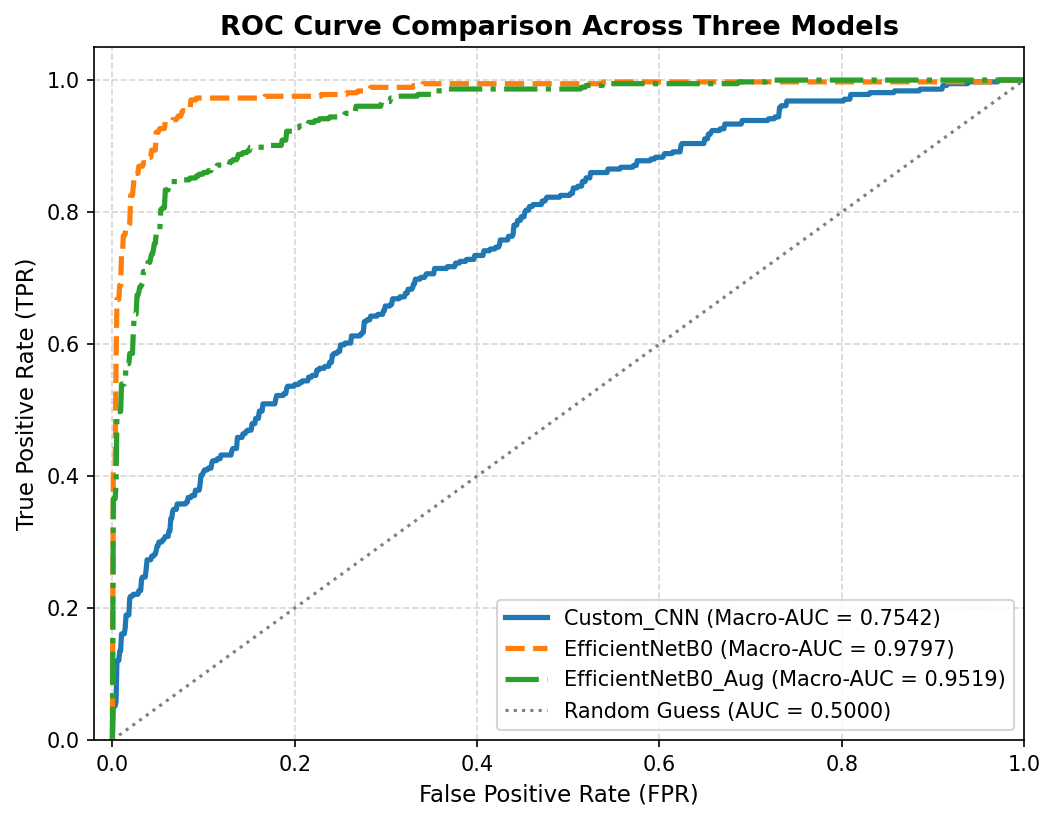

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

# 確認模型字典是否存在
if 'models_to_train' not in globals() or not isinstance(models_to_train, dict) or not models_to_train:
    raise RuntimeError("找不到模型字典 'models_to_train'！請確認您已經執行過訓練模型的 Cell。")

# 1. 取得測試集真實標籤並進行 One-Hot 編碼
y_true = np.concatenate([y.numpy() for x, y in test_ds], axis=0)
if y_true.ndim > 1:
    y_true = np.argmax(y_true, axis=1)

n_classes = len(class_names)
y_true_bin = label_binarize(y_true, classes=range(n_classes))

# 2. 建立畫布並設定三個模型的專屬顏色與線條樣式
plt.figure(figsize=(8, 6), dpi=150)
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']  # 藍、橘、綠
linestyles = ['-', '--', '-.']

# 用於計算 Macro-average 的統一 FPR 基準軸
mean_fpr = np.linspace(0, 1, 1000)

# 3. 依序計算每個模型的整體 ROC 曲線並繪製
for (model_name, model), color, ls in zip(models_to_train.items(), colors, linestyles):
    y_pred_probs = model.predict(test_ds, verbose=0)

    # 相容二元分類與多元分類
    if n_classes == 2:
        fpr, tpr, _ = roc_curve(y_true, y_pred_probs[:, 1])
        roc_auc = auc(fpr, tpr)
    else:
        # 計算每個類別的 ROC 曲線並透過內插法取 Macro 平均
        tprs = []
        aucs = []
        for i in range(n_classes):
            fpr_i, tpr_i, _ = roc_curve(y_true_bin[:, i], y_pred_probs[:, i])
            interp_tpr = np.interp(mean_fpr, fpr_i, tpr_i)
            interp_tpr[0] = 0.0
            tprs.append(interp_tpr)
            aucs.append(auc(fpr_i, tpr_i))

        fpr = mean_fpr
        tpr = np.mean(tprs, axis=0)
        tpr[-1] = 1.0
        roc_auc = auc(fpr, tpr)

    # 繪製該模型的 ROC 曲線
    plt.plot(
        fpr,
        tpr,
        color=color,
        linestyle=ls,
        linewidth=2.5,
        label=f'{model_name} (Macro-AUC = {roc_auc:.4f})'
    )

# 4. 繪製對角基準線與圖表美化
plt.plot([0, 1], [0, 1], color='gray', linestyle=':', linewidth=1.5, label='Random Guess (AUC = 0.5000)')
plt.xlim([-0.02, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=11)
plt.ylabel('True Positive Rate (TPR)', fontsize=11)
plt.title('ROC Curve Comparison Across Three Models', fontsize=13, fontweight='bold')
plt.legend(loc="lower right", fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)

# 5. 保存與顯示圖片
save_path = '/kaggle/working/roc_curve_comparison.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"Saved: {save_path}")
plt.show()